# I am experimenting with VQE

In [1]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

In [2]:
theta= np.pi/2

qc= QuantumCircuit(1)

qc.ry(theta,0)

print(qc.draw())


   ┌─────────┐
q: ┤ Ry(π/2) ├
   └─────────┘


In [3]:
state= Statevector.from_instruction(qc)
print("Quantum state:", state.data)

# Analytical calculation
expected_state = np.array([
    np.cos(theta / 2),
    np.sin(theta / 2)
])

print("Analytical state:", expected_state)

Quantum state: [0.70710678+0.j 0.70710678+0.j]
Analytical state: [0.70710678 0.70710678]


In [4]:
from qiskit.quantum_info import SparsePauliOp

H = SparsePauliOp.from_list([
    ("Z", 1.0),
    ("X", 1.0)
])

print(H)
print(H.to_matrix())

SparsePauliOp(['Z', 'X'],
              coeffs=[1.+0.j, 1.+0.j])
[[ 1.+0.j  1.+0.j]
 [ 1.+0.j -1.+0.j]]


In [5]:
energy = state.expectation_value(H).real

print("Energy:", energy)

Energy: 1.0000000000000002


In [6]:
def energy_function(theta):
    qc = QuantumCircuit(1)
    qc.ry(float(theta), 0)

    state = Statevector.from_instruction(qc)

    return float(state.expectation_value(H).real)

print(energy_function(0))
print(energy_function(np.pi / 2))
print(energy_function(-3 * np.pi / 4))

1.0
1.0000000000000002
-1.4142135623730951


In [7]:
from scipy.optimize import minimize
energy_history = []

def cost_function(params):
    theta = params[0]

    energy = energy_function(theta)
    energy_history.append(energy)

    return energy

result = minimize(
    cost_function,
    x0=np.array([0.0]),
    method="COBYLA",
    options={"maxiter": 200, "tol": 1e-8}
)

print("Optimal theta:", result.x[0])
print("VQE energy:", result.fun)
print("Exact energy:", -np.sqrt(2))

Optimal theta: -2.356194499999999
VQE energy: -1.414213562373095
Exact energy: -1.4142135623730951


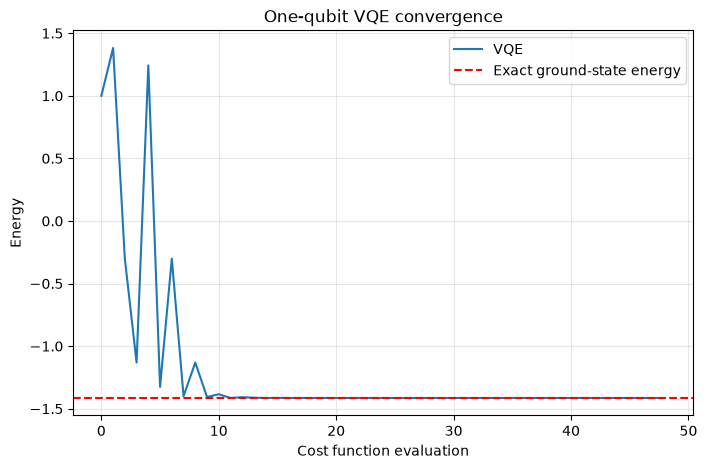

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(energy_history, label="VQE")
plt.axhline(
    -np.sqrt(2),
    linestyle="--",
    color="red",
    label="Exact ground-state energy"
)

plt.xlabel("Cost function evaluation")
plt.ylabel("Energy")
plt.title("One-qubit VQE convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

----

In [9]:

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from scipy.optimize import minimize

# Physical parameters, expressed as E/h in GHz
EC = 0.25
EJ_over_EC = 40
EJ = EJ_over_EC * EC
ng = 0.0


n_cutoff = 7
charges = np.arange(-n_cutoff, n_cutoff + 1)

def transmon_hamiltonian(charges, EC, EJ, ng):
    diagonal = 4 * EC * (charges - ng)**2

    H = np.diag(diagonal)

    hopping = -EJ / 2

    for i in range(len(charges) - 1):
        H[i, i+1] = hopping
        H[i+1, i] = hopping

    return H

H_charge = transmon_hamiltonian(charges, EC, EJ, ng)

print("Hamiltonian dimension:", H_charge.shape)
print(H_charge)

Hamiltonian dimension: (15, 15)
[[49. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-5. 36. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -5. 25. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. -5. 16. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -5.  9. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -5.  4. -5.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -5.  1. -5.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. -5.  0. -5.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. -5.  1. -5.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0. -5.  4. -5.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0. -5.  9. -5.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 16. -5.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 25. -5.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 36. -5.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 49.]]


In [10]:
exact_energies, exact_states = np.linalg.eigh(H_charge)

E0_exact = exact_energies[0]

print("Exact ground-state energy:", E0_exact, "GHz")
print("First excited energy:", exact_energies[1], "GHz")
print("Second excited energy:", exact_energies[2], "GHz")


Exact ground-state energy: -7.828347517111601 GHz
First excited energy: -3.6227658036667414 GHz
Second excited energy: 0.2885708262509847 GHz


In [11]:
n_qubits = 4
dim = 2**n_qubits

padding_energy = exact_energies[-1] + 100.0

H_padded = np.eye(dim) * padding_energy
H_padded[:len(charges), :len(charges)] = H_charge

# Convert matrix into a sum of Pauli operators
H_qubit = SparsePauliOp.from_operator(H_padded)

print("Number of qubits:", n_qubits)
print("Number of Pauli terms:", len(H_qubit))
print(H_qubit)


Number of qubits: 4
Number of Pauli terms: 38
SparsePauliOp(['IIII', 'IIIX', 'IIIZ', 'IIXX', 'IIYY', 'IIZI', 'IIZX', 'IIZZ', 'IXXX', 'IXYY', 'IYXY', 'IYYX', 'IZII', 'IZIX', 'IZIZ', 'IZZI', 'IZZX', 'IZZZ', 'XXXX', 'XXYY', 'XYXY', 'XYYX', 'YXXY', 'YXYX', 'YYXX', 'YYYY', 'ZIII', 'ZIIX', 'ZIIZ', 'ZIZI', 'ZIZX', 'ZIZZ', 'ZZII', 'ZZIX', 'ZZIZ', 'ZZZI', 'ZZZX', 'ZZZZ'],
              coeffs=[26.9256178+0.j, -4.375    +0.j, -5.9256178+0.j, -2.5      +0.j,
 -2.5      +0.j, -6.4256178+0.j, -0.625    +0.j,  6.4256178+0.j,
 -1.25     +0.j,  1.25     -0.j, -1.25     +0.j, -1.25     +0.j,
 -7.4256178+0.j, -0.625    +0.j,  7.4256178+0.j,  9.4256178+0.j,
  0.625    +0.j, -5.4256178+0.j, -0.625    +0.j,  0.625    -0.j,
  0.625    -0.j,  0.625    -0.j, -0.625    +0.j, -0.625    +0.j,
 -0.625    +0.j,  0.625    +0.j, -9.4256178+0.j, -0.625    +0.j,
  9.4256178+0.j, 13.4256178+0.j,  0.625    +0.j, -5.4256178+0.j,
 21.4256178+0.j,  0.625    +0.j, -5.4256178+0.j, -5.4256178+0.j,
 -0.625    +0.j,  5.4256178+

In [12]:

def create_ansatz(n_qubits, layers=3):
    n_params = n_qubits * (layers + 1)
    theta = ParameterVector("theta", n_params)

    qc = QuantumCircuit(n_qubits)

    # Start from the physical charge state |n=0>
    # In our encoding, charge n=0 has basis index 7.
    zero_charge_index = n_cutoff

    for q in range(n_qubits):
        if (zero_charge_index >> q) & 1:
            qc.x(q)

    idx = 0

    for layer in range(layers):
        # Parameterised rotations
        for q in range(n_qubits):
            qc.ry(theta[idx], q)
            idx += 1

        # Entangling gates
        for q in range(n_qubits - 1):
            qc.cx(q, q + 1)

    # Final rotation layer
    for q in range(n_qubits):
        qc.ry(theta[idx], q)
        idx += 1

    return qc, theta


ansatz, theta = create_ansatz(n_qubits, layers=3)

print(ansatz.draw("text"))
print("Number of parameters:", len(theta))

          ┌───┐      ┌──────────────┐     ┌──────────────┐                »
q_0: ─────┤ X ├──────┤ Ry(theta[0]) ├──■──┤ Ry(theta[4]) ├────────────────»
          ├───┤      ├──────────────┤┌─┴─┐└──────────────┘┌──────────────┐»
q_1: ─────┤ X ├──────┤ Ry(theta[1]) ├┤ X ├───────■────────┤ Ry(theta[5]) ├»
          ├───┤      ├──────────────┤└───┘     ┌─┴─┐      └──────────────┘»
q_2: ─────┤ X ├──────┤ Ry(theta[2]) ├──────────┤ X ├─────────────■────────»
     ┌────┴───┴─────┐└──────────────┘          └───┘           ┌─┴─┐      »
q_3: ┤ Ry(theta[3]) ├──────────────────────────────────────────┤ X ├──────»
     └──────────────┘                                          └───┘      »
«                     ┌──────────────┐                                 »
«q_0: ───────■────────┤ Ry(theta[8]) ├────────────────────────■────────»
«          ┌─┴─┐      └──────────────┘┌──────────────┐      ┌─┴─┐      »
«q_1: ─────┤ X ├─────────────■────────┤ Ry(theta[9]) ├──────┤ X ├──────»
«     ┌────┴───┴─────┐  

In [13]:

energy_history = []

def cost_function(parameters):

    # Assign numerical parameters to the circuit
    bound_circuit = ansatz.assign_parameters(
        dict(zip(theta, parameters))
    )

    # Simulate the quantum state
    state = Statevector.from_instruction(bound_circuit)

    # Calculate energy
    energy = np.real(
        state.expectation_value(H_qubit)
    )

    energy_history.append(float(energy))

    return float(energy)


In [14]:

initial_parameters = np.zeros(len(theta))

result = minimize(
    fun=cost_function,
    x0=initial_parameters,
    method="COBYLA",
    options={
        "maxiter": 10000,
        "rhobeg": 0.3,
        "tol": 1e-7
    }
)

E0_vqe = result.fun

print("VQE ground-state energy:", E0_vqe)
print("Exact ground-state energy:", E0_exact)
print("Absolute error:", abs(E0_vqe - E0_exact))
print("Optimiser success:", result.success)

VQE ground-state energy: -7.826159537053804
Exact ground-state energy: -7.828347517111601
Absolute error: 0.0021879800577968567
Optimiser success: False


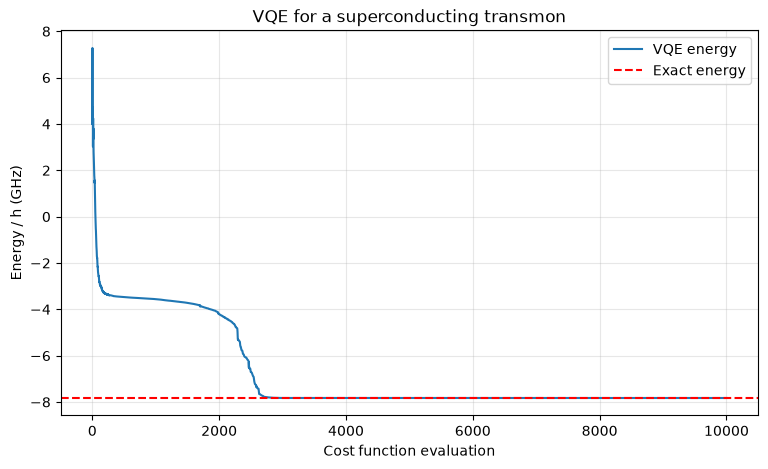

In [15]:

plt.figure(figsize=(9, 5))

plt.plot(energy_history, label="VQE energy")

plt.axhline(
    E0_exact,
    color="red",
    linestyle="--",
    label="Exact energy"
)

plt.xlabel("Cost function evaluation")
plt.ylabel("Energy / h (GHz)")
plt.title("VQE for a superconducting transmon")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [16]:

# Retrieve optimised VQE parameters
theta_0 = result.x.copy()

# Build optimised circuit
ground_circuit = ansatz.assign_parameters(
    dict(zip(theta, theta_0))
)

# Obtain ground-state vector
psi_0 = Statevector.from_instruction(
    ground_circuit
).data

print("Ground-state energy:", E0_vqe)
print("Statevector dimension:", len(psi_0))

Ground-state energy: -7.826159537053804
Statevector dimension: 16


In [17]:

def get_state(parameters):
    bound_circuit = ansatz.assign_parameters(
        dict(zip(theta, parameters))
    )

    return Statevector.from_instruction(
        bound_circuit
    ).data


def overlap_squared(psi_a, psi_b):
    return float(
        np.abs(np.vdot(psi_a, psi_b))**2
    )

In [18]:

def vqd_cost(
    parameters,
    previous_states,
    beta
):
    # Prepare candidate state
    psi = get_state(parameters)

    # Calculate physical energy
    energy = float(
        np.real(np.vdot(psi, H_qubit.to_matrix() @ psi))
    )

    # Calculate overlap penalties
    penalty = 0.0

    for previous_state in previous_states:
        overlap = overlap_squared(
            previous_state,
            psi
        )
        penalty += beta * overlap

    return energy + penalty

In [19]:

beta = 20.0

rng = np.random.default_rng(42)

initial_theta_1 = rng.uniform(
    -np.pi,
    np.pi,
    len(theta)
)

history_1 = []

def cost_first_excited(parameters):
    cost = vqd_cost(
        parameters,
        previous_states=[psi_0],
        beta=beta
    )

    history_1.append(cost)
    return cost


result_1 = minimize(
    cost_first_excited,
    x0=initial_theta_1,
    method="COBYLA",
    options={
        "maxiter": 5000,
        "rhobeg": 0.3,
        "tol": 1e-7
    }
)

theta_1 = result_1.x
psi_1 = get_state(theta_1)

# Physical energy (without penalty)
E1_vqd = float(
    np.real(np.vdot(psi_1, H_qubit.to_matrix() @ psi_1))
)

In [20]:

initial_theta_2 = rng.uniform(
    -np.pi,
    np.pi,
    len(theta)
)

history_2 = []

def cost_second_excited(parameters):
    cost = vqd_cost(
        parameters,
        previous_states=[psi_0, psi_1],
        beta=beta
    )

    history_2.append(cost)
    return cost


result_2 = minimize(
    cost_second_excited,
    x0=initial_theta_2,
    method="COBYLA",
    options={
        "maxiter": 5000,
        "rhobeg": 0.3,
        "tol": 1e-7
    }
)

theta_2 = result_2.x
psi_2 = get_state(theta_2)

E2_vqd = float(
    np.real(np.vdot(psi_2, H_qubit.to_matrix() @ psi_2))
)

print("Second excited energy (VQD):", E2_vqd)
print("Second excited energy (exact):", exact_energies[2])

print("Overlap with ground state:",
      overlap_squared(psi_0, psi_2))

print("Overlap with first excited state:",
      overlap_squared(psi_1, psi_2))

Second excited energy (VQD): 0.44225028607485234
Second excited energy (exact): 0.2885708262509847
Overlap with ground state: 4.674073072883425e-06
Overlap with first excited state: 5.35149462571309e-06


In [21]:

import pandas as pd

comparison = pd.DataFrame({
    "State": ["Ground", "First excited", "Second excited"],
    "Exact (GHz)": exact_energies[:3],
    "VQE/VQD (GHz)": [E0_vqe, E1_vqd, E2_vqd]
})

comparison["Absolute error (GHz)"] = np.abs(
    comparison["VQE/VQD (GHz)"] -
    comparison["Exact (GHz)"]
)

print(comparison.to_string(index=False))


         State  Exact (GHz)  VQE/VQD (GHz)  Absolute error (GHz)
        Ground    -7.828348      -7.826160              0.002188
 First excited    -3.622766      -3.615295              0.007470
Second excited     0.288571       0.442250              0.153679


In [22]:

import numpy as np
from scipy.linalg import eigh

from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import real_amplitudes
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA

# ==========================================
# 1. Parameters (energies in GHz, H/h)
# ==========================================

EC1 = 0.25
EJ1 = 15.0

EC2 = 0.27
EJ2 = 16.0

ng1 = 0.0
ng2 = 0.0

g = 0.05
nmax = 2

# ==========================================
# 2. Single-transmon Hamiltonian
# ==========================================

def transmon_hamiltonian(EC, EJ, ng, nmax):
    n = np.arange(-nmax, nmax + 1)
    d = len(n)

    # Charging energy
    H_charge = np.diag(4 * EC * (n - ng)**2)

    # Josephson energy: -EJ cos(phi)
    # cos(phi) connects adjacent charge states
    H_josephson = np.zeros((d, d))

    for i in range(d - 1):
        H_josephson[i, i + 1] = -EJ / 2
        H_josephson[i + 1, i] = -EJ / 2

    H = H_charge + H_josephson
    N = np.diag(n)

    return H, N


# ==========================================
# 3. Double-transmon Hamiltonian
# ==========================================

H1, N1 = transmon_hamiltonian(EC1, EJ1, ng1, nmax)
H2, N2 = transmon_hamiltonian(EC2, EJ2, ng2, nmax)

d = 2 * nmax + 1
I = np.eye(d)

H_double = (
    np.kron(H1, I)
    + np.kron(I, H2)
    + g * np.kron(N1, N2)
)

# ==========================================
# 4. Embed into qubit Hilbert space
# ==========================================

D = H_double.shape[0]
num_qubits = int(np.ceil(np.log2(D)))
padded_dim = 2**num_qubits

# High-energy penalty for unused basis states
penalty = 1000.0

H_padded = penalty * np.eye(padded_dim)
H_padded[:D, :D] = H_double

print("Physical dimension:", D)
print("Number of qubits:", num_qubits)

# ==========================================
# 5. Convert to Pauli operators
# ==========================================

H_pauli = SparsePauliOp.from_operator(H_padded).simplify()

print("Number of Pauli terms:", len(H_pauli))

# ==========================================
# 6. Classical exact diagonalisation
# ==========================================

eigenvalues, eigenvectors = eigh(H_double)
E_exact = eigenvalues[0]

print("Exact ground-state energy:", E_exact)

# ==========================================
# 7. VQE ansatz and optimiser
# ==========================================

ansatz = real_amplitudes(
    num_qubits=num_qubits,
    reps=3,
    entanglement="full"
)

estimator = StatevectorEstimator()

optimizer = COBYLA(maxiter=1000)

# ==========================================
# 8. Run VQE
# ==========================================

vqe = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    initial_point=np.random.default_rng(42).uniform(
        -np.pi, np.pi, ansatz.num_parameters
    )
)

result = vqe.compute_minimum_eigenvalue(H_pauli)

E_vqe = float(np.real(result.eigenvalue))

# ==========================================
# 9. Compare results
# ==========================================

print("\n===== RESULTS =====")
print(f"Exact energy: {E_exact:.8f} GHz")
print(f"VQE energy:   {E_vqe:.8f} GHz")
print(f"Error:        {abs(E_vqe - E_exact):.8f} GHz")


Physical dimension: 25
Number of qubits: 5
Number of Pauli terms: 154
Exact ground-state energy: -24.67494247258858

===== RESULTS =====
Exact energy: -24.67494247 GHz
VQE energy:   -21.08097370 GHz
Error:        3.59396877 GHz


===== IMPROVED VQE =====
Exact energy: -24.6749424726 GHz
VQE energy:   -23.2625286827 GHz
Error:        1.4124137899 GHz
Evaluations:  1428


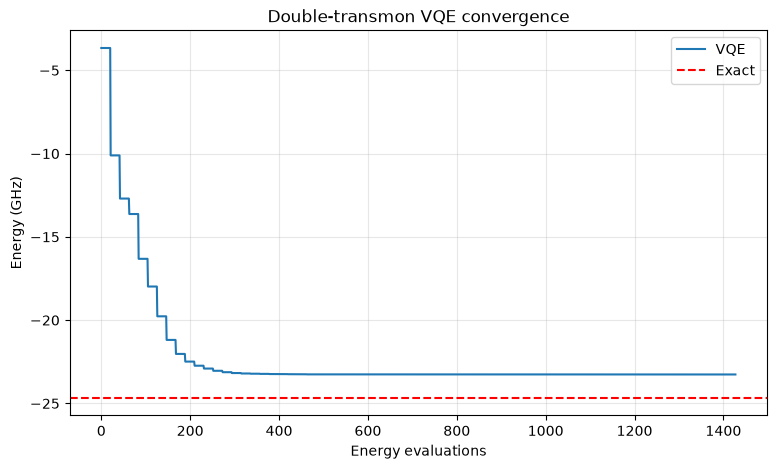

In [23]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import eigh
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import real_amplitudes
from qiskit.circuit import QuantumCircuit
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import L_BFGS_B

# 1. Reference state from uncoupled transmons
e1, v1 = eigh(H1)
e2, v2 = eigh(H2)

psi_ref = np.kron(v1[:, 0], v2[:, 0])

# 2. Shift the physical Hamiltonian
D = H_double.shape[0]
num_qubits = int(np.ceil(np.log2(D)))
padded_dim = 2**num_qubits

shift = e1[0] + e2[0]
H_shifted = H_double - shift * np.eye(D)

# Padding penalty relative to shifted energies
penalty = max(10.0, np.linalg.eigvalsh(H_shifted)[-1] + 10.0)

H_padded = penalty * np.eye(padded_dim)
H_padded[:D, :D] = H_shifted

H_pauli = SparsePauliOp.from_operator(H_padded).simplify(atol=1e-10)

# 3. Prepare physically motivated initial state
psi_padded = np.zeros(padded_dim, dtype=complex)
psi_padded[:D] = psi_ref

initial_circuit = QuantumCircuit(num_qubits)
initial_circuit.initialize(psi_padded, range(num_qubits))

# 4. Variational ansatz
variational = real_amplitudes(
    num_qubits=num_qubits,
    reps=3,
    entanglement="full"
)

ansatz = initial_circuit.compose(variational)

# Zero parameters mean we begin at psi_ref
initial_point = np.zeros(ansatz.num_parameters)

# 5. Track convergence
history = []

def callback(eval_count, parameters, energy, metadata):
    history.append(float(np.real(energy)) + shift)

# 6. VQE
vqe = VQE(
    estimator=StatevectorEstimator(),
    ansatz=ansatz,
    optimizer=L_BFGS_B(maxiter=1500),
    initial_point=initial_point,
    callback=callback
)

result = vqe.compute_minimum_eigenvalue(H_pauli)

E_vqe = float(np.real(result.eigenvalue)) + shift
E_exact = np.linalg.eigvalsh(H_double)[0]

# 7. Results
print("===== IMPROVED VQE =====")
print(f"Exact energy: {E_exact:.10f} GHz")
print(f"VQE energy:   {E_vqe:.10f} GHz")
print(f"Error:        {abs(E_vqe-E_exact):.10f} GHz")
print(f"Evaluations:  {len(history)}")

# 8. Convergence plot
plt.figure(figsize=(9, 5))
plt.plot(history, label="VQE")
plt.axhline(E_exact, color="red",
            linestyle="--", label="Exact")

plt.xlabel("Energy evaluations")
plt.ylabel("Energy (GHz)")
plt.title("Double-transmon VQE convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


g=0.000 | VQE=-24.37956931 | Exact=-24.67478724 | Error=2.952e-01 | Leakage=4.472e-04
g=0.005 | VQE=-24.38022406 | Exact=-24.67478879 | Error=2.946e-01 | Leakage=4.466e-04
g=0.010 | VQE=-24.38088099 | Exact=-24.67479345 | Error=2.939e-01 | Leakage=4.460e-04
g=0.015 | VQE=-24.38154011 | Exact=-24.67480121 | Error=2.933e-01 | Leakage=4.453e-04
g=0.020 | VQE=-24.38220141 | Exact=-24.67481207 | Error=2.926e-01 | Leakage=4.447e-04
g=0.025 | VQE=-24.38286489 | Exact=-24.67482605 | Error=2.920e-01 | Leakage=4.440e-04
g=0.030 | VQE=-24.38353056 | Exact=-24.67484312 | Error=2.913e-01 | Leakage=4.434e-04
g=0.035 | VQE=-24.38419841 | Exact=-24.67486330 | Error=2.907e-01 | Leakage=4.428e-04
g=0.040 | VQE=-24.38486843 | Exact=-24.67488659 | Error=2.900e-01 | Leakage=4.421e-04
g=0.045 | VQE=-24.38554064 | Exact=-24.67491298 | Error=2.894e-01 | Leakage=4.415e-04
g=0.050 | VQE=-24.38621503 | Exact=-24.67494247 | Error=2.887e-01 | Leakage=4.408e-04


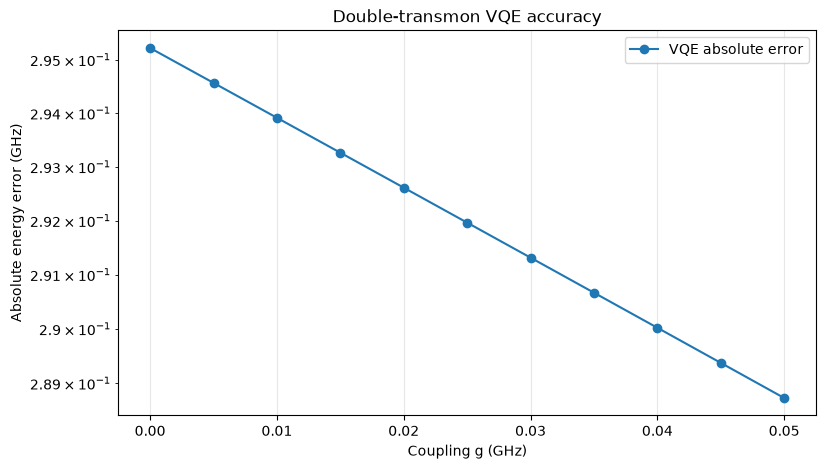

In [24]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import eigh
from qiskit import QuantumCircuit
from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import L_BFGS_B

# ==========================================
# 1. Construct Hamiltonian
# ==========================================

d = H1.shape[0]
I = np.eye(d)

H0 = np.kron(H1, I) + np.kron(I, H2)
V = np.kron(N1, N2)

D = H0.shape[0]
num_qubits = int(np.ceil(np.log2(D)))
padded_dim = 2**num_qubits

# ==========================================
# 2. Initial physical reference state
# ==========================================

e1, v1 = eigh(H1)
e2, v2 = eigh(H2)

psi0 = np.kron(v1[:, 0], v2[:, 0])

psi_padded = np.zeros(padded_dim, dtype=complex)
psi_padded[:D] = psi0

initial_state = QuantumCircuit(num_qubits)
initial_state.initialize(
    psi_padded,
    range(num_qubits)
)

# ==========================================
# 3. Variational circuit
# ==========================================

variational = real_amplitudes(
    num_qubits=num_qubits,
    reps=4,
    entanglement="full"
)

ansatz = initial_state.compose(variational)

theta = np.zeros(ansatz.num_parameters)

# ==========================================
# 4. Coupling continuation
# ==========================================

g_values = np.linspace(0, 0.05, 11)

vqe_energies = []
exact_energies = []
errors = []
leakages = []

for g in g_values:

    H = H0 + g * V

    # Shift energies to improve numerical scaling
    shift = e1[0] + e2[0]
    H_shifted = H - shift * np.eye(D)

    # Unused computational states must stay high
    penalty = max(
        10.0,
        np.linalg.eigvalsh(H_shifted)[-1] + 10.0
    )

    H_padded = penalty * np.eye(padded_dim)
    H_padded[:D, :D] = H_shifted

    H_pauli = SparsePauliOp.from_operator(
        H_padded
    ).simplify(atol=1e-10)

    vqe = VQE(
        estimator=StatevectorEstimator(),
        ansatz=ansatz,
        optimizer=L_BFGS_B(
            maxiter=1500,
            maxfun=20000,
            ftol=1e-12
        ),
        initial_point=theta
    )

    result = vqe.compute_minimum_eigenvalue(
        H_pauli
    )

    # Warm-start next coupling
    theta = np.asarray(result.optimal_point)

    E_vqe = float(np.real(result.eigenvalue)) + shift
    E_exact = eigh(H, eigvals_only=True)[0]

    # Check population outside physical basis
    final_circuit = ansatz.assign_parameters(theta)
    psi = Statevector.from_instruction(
        final_circuit
    ).data

    leakage = np.sum(np.abs(psi[D:])**2)

    vqe_energies.append(E_vqe)
    exact_energies.append(E_exact)
    errors.append(abs(E_vqe - E_exact))
    leakages.append(leakage)

    print(
        f"g={g:.3f} | "
        f"VQE={E_vqe:.8f} | "
        f"Exact={E_exact:.8f} | "
        f"Error={errors[-1]:.3e} | "
        f"Leakage={leakage:.3e}"
    )

# ==========================================
# 5. Plot accuracy
# ==========================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.semilogy(
    g_values,
    np.maximum(errors, 1e-14),
    marker="o",
    label="VQE absolute error"
)

ax.set_xlabel("Coupling g (GHz)")
ax.set_ylabel("Absolute energy error (GHz)")
ax.set_title("Double-transmon VQE accuracy")
ax.grid(alpha=0.3)
ax.legend()

plt.show()


In [25]:
# Diagonalise isolated transmons
E1, U1 = np.linalg.eigh(H1)
E2, U2 = np.linalg.eigh(H2)

# Keep four levels per transmon
levels = 4

E1_low = E1[:levels]
E2_low = E2[:levels]

U1_low = U1[:, :levels]
U2_low = U2[:, :levels]

# Charge operators in the energy eigenbasis
N1_low = U1_low.conj().T @ N1 @ U1_low
N2_low = U2_low.conj().T @ N2 @ U2_low

# Construct effective double-transmon Hamiltonian
H_effective = (
    np.kron(np.diag(E1_low), np.eye(levels))
    + np.kron(np.eye(levels), np.diag(E2_low))
    + g * np.kron(N1_low, N2_low)
)

# Convert to four-qubit operator
H_pauli = SparsePauliOp.from_operator(
    H_effective
).simplify()

print("Qubits:", H_pauli.num_qubits)
print("Pauli terms:", len(H_pauli))

Qubits: 4
Pauli terms: 23


Hamiltonian dimension: (16, 16)
Hermitian: True
Number of qubits: 4
Linear Pauli terms: 5
Nonlinear Pauli terms: 41
lambda=0.00 | E=0.00000000 GHz | Variance=0.000e+00
lambda=0.10 | E=-0.00483811 GHz | Variance=2.755e-05
lambda=0.20 | E=-0.00971376 GHz | Variance=1.118e-04
lambda=0.30 | E=-0.01462766 GHz | Variance=2.553e-04
lambda=0.40 | E=-0.01958056 GHz | Variance=4.606e-04
lambda=0.50 | E=-0.02457319 GHz | Variance=7.304e-04
lambda=0.60 | E=-0.02960635 GHz | Variance=1.068e-03
lambda=0.70 | E=-0.03468084 GHz | Variance=1.475e-03
lambda=0.80 | E=-0.03979747 GHz | Variance=1.956e-03
lambda=0.90 | E=-0.04495711 GHz | Variance=2.514e-03
lambda=1.00 | E=-0.05016063 GHz | Variance=3.151e-03

===== FINAL VQE RESULTS =====
VQE energy: -0.0501606315 GHz
Energy variance: 3.151e-03 GHz^2
Ansatz depth: 27

===== CLASSICAL VALIDATION =====
Exact ground energy: -0.0503169893 GHz
VQE ground energy:   -0.0501606315 GHz
Absolute error:      0.0001563577 GHz
Exact first transition: 4.83461310 GHz


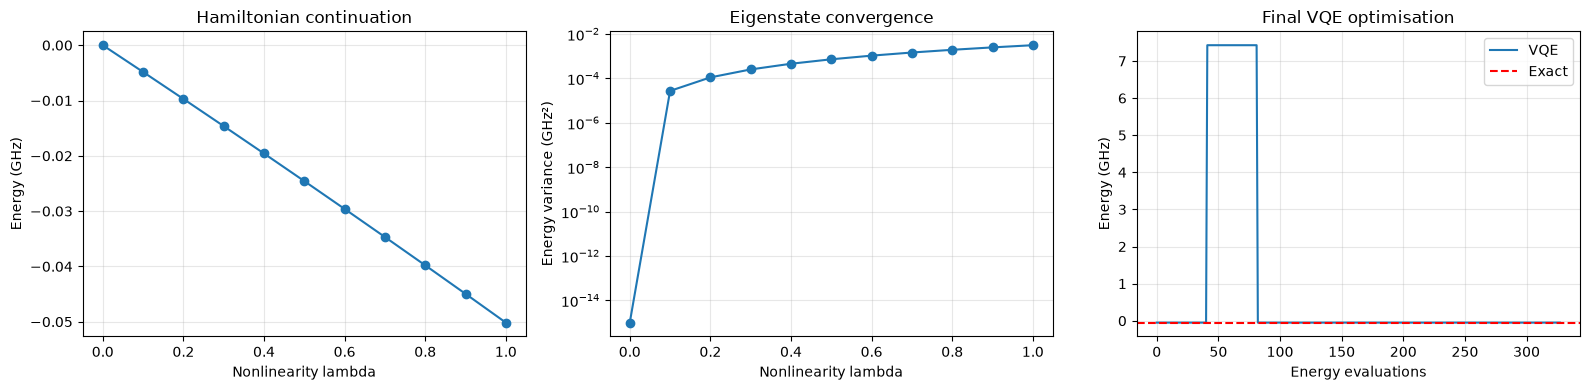

In [26]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import eigh, cosm

from qiskit import QuantumCircuit
from qiskit.quantum_info import (
    SparsePauliOp,
    Statevector
)
from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorEstimator

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import L_BFGS_B


# =====================================================
# 1. EPR PARAMETERS
# =====================================================

# Illustrative parameters; replace with actual EPR data

frequencies = np.array([5.0, 5.4])  # GHz

# Josephson energies EJ/h, in GHz
EJ = np.array([15.0])

# phi_zpf[mode, junction]
phi_zpf = np.array([
    [0.35],
    [0.20]
])

# Fock truncation per mode
fock_dim = 4

# Continuation and VQE settings
continuation_steps = 11
ansatz_reps = 4
maxiter = 1500


# =====================================================
# 2. BOSONIC OPERATORS
# =====================================================

def annihilation(d):
    return np.diag(np.sqrt(np.arange(1, d)), 1)


def embed_operator(op, mode, dims):
    """Embed a local operator into the full Hilbert space."""
    operators = []

    for m, d in enumerate(dims):
        if m == mode:
            operators.append(op)
        else:
            operators.append(np.eye(d))

    result = operators[0]

    for operator in operators[1:]:
        result = np.kron(result, operator)

    return result


def construct_mode_operators(num_modes, d):
    dims = [d] * num_modes
    a_local = annihilation(d)

    a_ops = []
    n_ops = []

    for m in range(num_modes):
        a = embed_operator(a_local, m, dims)
        a_ops.append(a)
        n_ops.append(a.conj().T @ a)

    return a_ops, n_ops


# =====================================================
# 3. CONSTRUCT EPR HAMILTONIAN
# =====================================================

def construct_epr_hamiltonian(
    frequencies,
    EJ,
    phi_zpf,
    fock_dim
):
    frequencies = np.asarray(frequencies, dtype=float)
    EJ = np.asarray(EJ, dtype=float)
    phi_zpf = np.asarray(phi_zpf, dtype=float)

    num_modes = len(frequencies)
    num_junctions = len(EJ)

    assert phi_zpf.shape == (
        num_modes, num_junctions
    )

    D = fock_dim**num_modes
    I = np.eye(D)

    a_ops, n_ops = construct_mode_operators(
        num_modes, fock_dim
    )

    # Linear Hamiltonian
    H_linear = np.zeros((D, D), dtype=complex)

    for m in range(num_modes):
        H_linear += frequencies[m] * n_ops[m]

    # Nonlinear Josephson contribution
    H_nonlinear = np.zeros((D, D), dtype=complex)

    for j in range(num_junctions):

        phi = np.zeros((D, D), dtype=complex)

        for m in range(num_modes):
            phi += phi_zpf[m, j] * (
                a_ops[m] + a_ops[m].conj().T
            )

        # Full cosine nonlinearity
        H_nonlinear += -EJ[j] * (
            cosm(phi)
            - I
            + 0.5 * (phi @ phi)
        )

    H = H_linear + H_nonlinear

    # Enforce Hermiticity numerically
    H_linear = (H_linear + H_linear.conj().T) / 2
    H_nonlinear = (
        H_nonlinear + H_nonlinear.conj().T
    ) / 2
    H = (H + H.conj().T) / 2

    return H, H_linear, H_nonlinear


H_epr, H_linear, H_nonlinear = (
    construct_epr_hamiltonian(
        frequencies,
        EJ,
        phi_zpf,
        fock_dim
    )
)

print("Hamiltonian dimension:", H_epr.shape)
print("Hermitian:", np.allclose(
    H_epr, H_epr.conj().T
))


# =====================================================
# 4. QUBIT ENCODING
# =====================================================

def encode_hamiltonians(H0, H1):
    D = H0.shape[0]

    n_qubits = int(np.ceil(np.log2(D)))
    padded_dim = 2**n_qubits

    # Physical Hamiltonian shifted by its vacuum energy
    vacuum_energy = float(np.real(H0[0, 0]))
    H0_shifted = H0 - vacuum_energy * np.eye(D)

    # Padding energy above the physical spectrum
    full_H = H0_shifted + H1
    upper_bound = max(
        np.linalg.eigvalsh(H0_shifted)[-1],
        np.linalg.eigvalsh(full_H)[-1]
    )

    penalty = max(10.0, upper_bound + 10.0)

    H0_padded = penalty * np.eye(
        padded_dim, dtype=complex
    )
    H0_padded[:D, :D] = H0_shifted

    H1_padded = np.zeros(
        (padded_dim, padded_dim), dtype=complex
    )
    H1_padded[:D, :D] = H1

    H0_pauli = SparsePauliOp.from_operator(
        H0_padded
    ).simplify(atol=1e-10)

    H1_pauli = SparsePauliOp.from_operator(
        H1_padded
    ).simplify(atol=1e-10)

    return (
        H0_pauli,
        H1_pauli,
        n_qubits,
        vacuum_energy
    )


H0_pauli, H1_pauli, n_qubits, shift = (
    encode_hamiltonians(
        H_linear,
        H_nonlinear
    )
)

print("Number of qubits:", n_qubits)
print("Linear Pauli terms:", len(H0_pauli))
print("Nonlinear Pauli terms:", len(H1_pauli))


# =====================================================
# 5. VQE ANSATZ
# =====================================================

# The zero-parameter circuit prepares |000...0>.
# RY and RZ rotations allow complex amplitudes.

ansatz = efficient_su2(
    num_qubits=n_qubits,
    su2_gates=["ry", "rz"],
    entanglement="full",
    reps=ansatz_reps
)

theta = np.zeros(ansatz.num_parameters)

estimator = StatevectorEstimator()


# =====================================================
# 6. HAMILTONIAN CONTINUATION
# =====================================================

lambda_values = np.linspace(
    0, 1, continuation_steps
)

continuation_energies = []
continuation_variances = []
all_histories = []

for lam in lambda_values:

    H_lam = (
        H0_pauli + lam * H1_pauli
    ).simplify(atol=1e-10)

    history = []

    def callback(
        eval_count,
        parameters,
        energy,
        metadata
    ):
        history.append(
            float(np.real(energy)) + shift
        )

    optimizer = L_BFGS_B(
        maxiter=maxiter,
        maxfun=20000,
        ftol=1e-12
    )

    vqe = VQE(
        estimator=estimator,
        ansatz=ansatz,
        optimizer=optimizer,
        initial_point=theta,
        callback=callback
    )

    result = vqe.compute_minimum_eigenvalue(
        H_lam
    )

    # Warm-start next continuation step
    theta = np.asarray(
        result.optimal_point, dtype=float
    )

    energy = float(
        np.real(result.eigenvalue)
    ) + shift

    # Obtain optimised state
    circuit = ansatz.assign_parameters(theta)
    psi = Statevector.from_instruction(circuit).data

    H_matrix = H_lam.to_matrix()

    expectation = np.vdot(
        psi, H_matrix @ psi
    )

    variance = np.real(
        np.vdot(
            psi,
            H_matrix @ (H_matrix @ psi)
        )
        - abs(expectation)**2
    )

    continuation_energies.append(energy)
    continuation_variances.append(
        max(float(variance), 0.0)
    )
    all_histories.append(history)

    print(
        f"lambda={lam:.2f} | "
        f"E={energy:.8f} GHz | "
        f"Variance={variance:.3e}"
    )


# =====================================================
# 7. FINAL VQE STATE
# =====================================================

final_circuit = ansatz.assign_parameters(theta)
psi_vqe = Statevector.from_instruction(
    final_circuit
).data

E_vqe = continuation_energies[-1]

# Energy variance
H_final = (H0_pauli + H1_pauli).to_matrix()

E_shifted = np.real(
    np.vdot(psi_vqe, H_final @ psi_vqe)
)

variance = np.real(
    np.vdot(
        psi_vqe,
        H_final @ (H_final @ psi_vqe)
    ) - E_shifted**2
)

print("\n===== FINAL VQE RESULTS =====")
print(f"VQE energy: {E_vqe:.10f} GHz")
print(f"Energy variance: {max(variance, 0):.3e} GHz^2")
print(f"Ansatz depth: {ansatz.decompose().depth()}")


# =====================================================
# 8. EXACT DIAGONALISATION (VALIDATION ONLY)
# =====================================================

exact_eigenvalues, exact_eigenvectors = eigh(H_epr)

E_exact = exact_eigenvalues[0]
E1_exact = exact_eigenvalues[1]

print("\n===== CLASSICAL VALIDATION =====")
print(f"Exact ground energy: {E_exact:.10f} GHz")
print(f"VQE ground energy:   {E_vqe:.10f} GHz")
print(f"Absolute error:      {abs(E_vqe-E_exact):.10f} GHz")

print(
    f"Exact first transition: "
    f"{E1_exact-E_exact:.8f} GHz"
)


# =====================================================
# 9. PLOTS
# =====================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Continuation energies
axes[0].plot(
    lambda_values,
    continuation_energies,
    "o-"
)
axes[0].set_xlabel("Nonlinearity lambda")
axes[0].set_ylabel("Energy (GHz)")
axes[0].set_title("Hamiltonian continuation")
axes[0].grid(alpha=0.3)

# Energy variance
axes[1].semilogy(
    lambda_values,
    np.maximum(continuation_variances, 1e-15),
    "o-"
)
axes[1].set_xlabel("Nonlinearity lambda")
axes[1].set_ylabel("Energy variance (GHz²)")
axes[1].set_title("Eigenstate convergence")
axes[1].grid(alpha=0.3)

# Final optimisation history
axes[2].plot(
    all_histories[-1],
    label="VQE"
)
axes[2].axhline(
    E_exact,
    linestyle="--",
    color="red",
    label="Exact"
)
axes[2].set_xlabel("Energy evaluations")
axes[2].set_ylabel("Energy (GHz)")
axes[2].set_title("Final VQE optimisation")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()
